In [1]:

import pandas as pd
import numpy as np

# Make the sample data reproducible
rng = np.random.default_rng(42)

# Create 200 fictional financial transactions
transactions = pd.DataFrame({
    "Transaction_ID": range(1001, 1201),
    "Vendor": rng.choice(
        ["Amazon", "Staples", "Office Depot", "Microsoft", "Dell"],
        200
    ),
    "Amount": rng.uniform(20, 500, 200).round(2),
    "Department": rng.choice(
        ["Accounting", "IT", "HR", "Operations"],
        200
    )
})

# Insert some unusual transactions for testing
transactions.loc[10, "Amount"] = 9500
transactions.loc[45, "Amount"] = 12000
transactions.loc[100, "Amount"] = 15000

# Display the first 10 transactions
print("Financial Transaction Dataset")
print("Total transactions:", len(transactions))

display(transactions.head(10))


Financial Transaction Dataset
Total transactions: 200


,Transaction_ID,Vendor,Amount,Department
0,1001,Amazon,456.12,HR
1,1002,Microsoft,355.86,Operations
2,1003,Microsoft,147.62,HR
3,1004,Office Depot,485.20,Accounting
4,1005,Office Depot,393.80,Operations
5,1006,Dell,364.11,HR
6,1007,Amazon,235.69,IT
7,1008,Microsoft,150.68,HR
8,1009,Staples,66.27,Operations
9,1010,Amazon,453.25,Operations


In [2]:

# Find the 10 biggest transactions
biggest = transactions.nlargest(10, "Amount")

print("TOP 10 BIGGEST TRANSACTIONS")
display(biggest)


TOP 10 BIGGEST TRANSACTIONS


,Transaction_ID,Vendor,Amount,Department
100,1101,Dell,15000.00,HR
45,1046,Dell,12000.00,IT
10,1011,Office Depot,9500.00,Operations
77,1078,Staples,496.34,Accounting
196,1197,Staples,490.19,Operations
101,1102,Amazon,486.48,HR
3,1004,Office Depot,485.20,Accounting
132,1133,Amazon,483.79,Operations
36,1037,Dell,480.11,Accounting
123,1124,Office Depot,478.70,Accounting


In [3]:

from sklearn.ensemble import IsolationForest

# Create our machine learning model
model = IsolationForest(
    contamination=0.02,
    random_state=42
)

# Teach the model using transaction amounts
transactions["AI_Result"] = model.fit_predict(
    transactions[["Amount"]]
)

# Find transactions the AI considers unusual
suspicious = transactions[
    transactions["AI_Result"] == -1
]

print("AI ANOMALY DETECTION RESULTS")
print("Unusual transactions found:", len(suspicious))

display(suspicious)


AI ANOMALY DETECTION RESULTS
Unusual transactions found: 4


,Transaction_ID,Vendor,Amount,Department,AI_Result
10,1011,Office Depot,9500.00,Operations,-1
45,1046,Dell,12000.00,IT,-1
77,1078,Staples,496.34,Accounting,-1
100,1101,Dell,15000.00,HR,-1


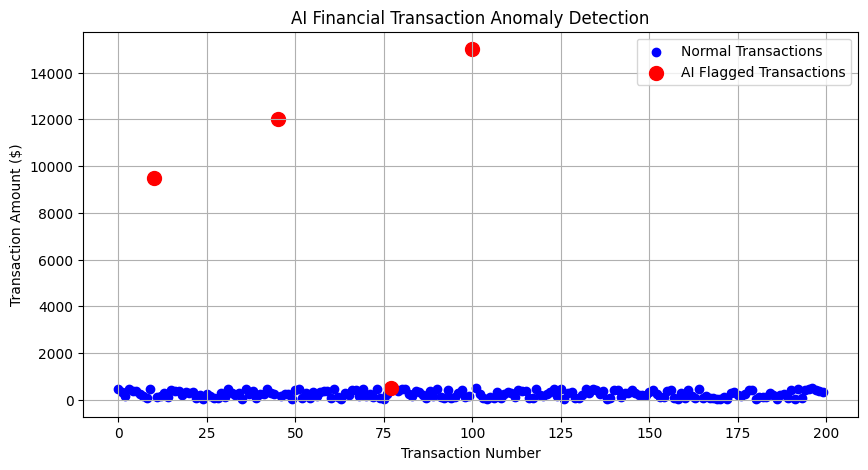

In [4]:

import matplotlib.pyplot as plt

# Create the chart
plt.figure(figsize=(10, 5))

# Normal transactions
normal = transactions[transactions["AI_Result"] == 1]

plt.scatter(
    normal.index,
    normal["Amount"],
    color="blue",
    label="Normal Transactions"
)

# Unusual transactions
plt.scatter(
    suspicious.index,
    suspicious["Amount"],
    color="red",
    label="AI Flagged Transactions",
    s=100
)

plt.title("AI Financial Transaction Anomaly Detection")
plt.xlabel("Transaction Number")
plt.ylabel("Transaction Amount ($)")
plt.legend()
plt.grid(True)

plt.show()


# AI-Powered Financial Transaction Anomaly Detection

## Project Overview
Built a Python machine-learning project that analyzes financial transactions and identifies unusual payments that may require additional audit review.

## Tools Used
Python, Pandas, NumPy, Scikit-learn, Matplotlib, and Google Colab.

## Project Results
- Analyzed 200 fictional financial transactions.
- Used the Isolation Forest machine-learning algorithm.
- Identified 4 unusual transactions.
- Created a chart highlighting flagged transactions.

## Audit Relevance
This project demonstrates how machine learning can help auditors identify unusual transactions for further investigation. Flagged transactions do not necessarily indicate fraud.

## Limitations
The project uses fictional data and analyzes transaction amounts only. It is a beginner-level prototype, not a validated fraud-detection system.